# DATA3320 Lecture 12 Class Demo: Introduction to Probability


**Business context:** A healthcare network wants to reason about uncertain events such as appointment attendance and daily service demand.

> This notebook moves from intuitive probability to simulations, counting, combined events, and a small decision-support case.


## Course-material references
This class demo expands and applies the following Week 7 materials:

- **Lecture 12 presentation:** `Lecture12_probability_review.ppt`
  - probability as a bridge between descriptive and inferential statistics
  - experiments, events, simple events, and sample spaces
  - empirical and equally likely probability
  - counting rules, permutations, and combinations
  - mutually exclusive events and probability distributions


### Online course links from the Week 7 guide
- [Lecture 12 recording](https://nait.video.yuja.com/V/Video?v=1349720&node=7568820&a=1255193436)
- [Original Lecture 12 notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture12_probability.ipynb)
- [Lecture 11–12 workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture11_12_Workbook.ipynb)
- [Workbook solution](https://colab.research.google.com/drive/1RvKxMns7J_ppjzlXISrwtBAxCAzTalBe?usp=sharing)




## Google Colab instructions
1. Download this `.ipynb` file.
2. Open [Google Colab](https://colab.research.google.com/).
3. Select **File → Upload notebook** and choose the downloaded file.
4. Run cells from top to bottom.
5. Complete each exercise before opening the hint or solution.
6. Save a copy to Google Drive if you want to retain your work.

All simulations and datasets are generated in the notebook.


## Learning outcomes
By the end of class, students should be able to:
1. Define experiment, outcome, event, and sample space.
2. Calculate probabilities for equally likely outcomes.
3. Explain experimental versus theoretical probability.
4. Use complements, unions, and intersections.
5. Distinguish mutually exclusive and independent events.
6. Apply multiplication counting, permutations, and combinations.
7. Build and interpret a discrete probability distribution.


## Theory: Probability as a model of uncertainty
Probability assigns a number from 0 to 1 to an event:
- 0 means impossible under the model.
- 1 means certain under the model.
- Values between 0 and 1 represent degrees of uncertainty.

Probability conclusions depend on assumptions. In a healthcare attendance model, assumptions may include a stable attendance probability and independence across appointments.


> **Presentation connection:** The Lecture 12 presentation describes probability as a bridge from descriptive statistics toward inferential reasoning. This notebook applies that bridge through simulations and healthcare planning.


### Theory reference
For equally likely outcomes:
$$
P(A)=\frac{|A|}{|S|}
$$

Complement rule:
$$P(A^c)=1-P(A)$$

Addition rule:
$$P(A\cup B)=P(A)+P(B)-P(A\cap B)$$

For independent events:
$$P(A\cap B)=P(A)P(B)$$

Expected value of a binomial count:
$$E(X)=np$$


## Today's learning path

1. **Appointment prediction challenge** (0–10 min)
2. **Experiments, outcomes, events, and sample spaces** (10–25 min)
3. **Learn probability through simulation** (25–45 min)
4. **Complements and combined events** (45–60 min)
5. **Counting choices efficiently** (60–72 min)
6. **Pause and reset** (72–77 min)
7. **Permutations and combinations** (77–88 min)
8. **Business probability and attendance simulation** (88–105 min)
9. **Exit check** (105–110 min)


## How to use this notebook
- Run cells in order.
- Predict before simulating.
- Expect simulation results to vary unless a random seed is used.
- Explain each probability in the context of the event.
- Treat model results as estimates based on assumptions, not guarantees.


In [7]:
# Environment and dependency check
# Required third-party packages: pandas, numpy, matplotlib
import sys
from importlib.util import find_spec

required_packages = ["pandas", "numpy", "matplotlib"]
missing_packages = [pkg for pkg in required_packages if find_spec(pkg) is None]

print("Python version:", sys.version.split()[0])
if missing_packages:
    raise ModuleNotFoundError(
        "Missing package(s): " + ", ".join(missing_packages) +
        ". Install them before running this notebook, for example: " +
        "pip install pandas numpy matplotlib"
    )
print("Dependency check passed:", ", ".join(required_packages))


Python version: 3.12.8
Dependency check passed: pandas, numpy, matplotlib


## 1. Appointment prediction challenge (0–10 min)

A clinic books 100 appointments. Historically, about 80% of booked appointments are attended.

### Stop and Predict
1. How many attendees would you expect?
2. Must exactly that number attend?
3. What factors could make tomorrow different from the historical pattern?
4. How could this estimate support staffing without becoming a guarantee?

In [7]:
import random
import itertools
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

random.seed(3320)
np.random.seed(3320)


## 2. Core vocabulary (10–25 min)
- **Experiment:** a repeatable process that produces an observation.
- **Outcome:** one possible result.
- **Sample space:** set of all possible outcomes.
- **Event:** one or more outcomes of interest.

For a fair six-sided die:
- Experiment: roll once.
- Sample space: `{1,2,3,4,5,6}`.
- Event A: roll an even number, `{2,4,6}`.


> **Presentation connection:** This section aligns with the presentation’s definitions of experiment, event, simple event, and sample space.


In [84]:
sample_space_die = {1, 2, 3, 4, 5, 6}
event_even = {2, 4, 6}
event_greater_than_3 = {4, 5, 6}
print("Sample space:", sample_space_die)
print("Even event:", event_even)
print("Greater than 3:", event_greater_than_3)


Sample space: {1, 2, 3, 4, 5, 6}
Even event: {2, 4, 6}
Greater than 3: {4, 5, 6}


### Try It 1 (6 min)
For one card drawn from cards labelled 1 through 10:
1. Write the sample space.
2. Define event A = “multiple of 3.”
3. Define event B = “greater than 6.”
4. Find the overlap between A and B.


<details><summary><strong>Click to show hint: Sample space exercise</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Sample space exercise</strong></summary>

$S=\{1,2,3,4,5,6,7,8,9,10\}$, $A=\{3,6,9\}$, $B=\{7,8,9,10\}$, and $A\cap B=\{9\}$. Therefore, the overlap contains one outcome.

</details>


<details><summary><strong>Click to show explanation: Sample space exercise</strong></summary>

A sample space contains every possible outcome. Events are subsets of that space, and the intersection contains outcomes that satisfy both event definitions.

</details>


In [11]:
S = set(range(1, 11))
A = {x for x in S if x % 3 == 0}
B = {x for x in S if x > 6}
print("S =", S)
print("A =", A)
print("B =", B)
print("A and B =", A & B)


S = {1, 2, 3, 4, 5, 6, 7, 8, 9, 10}
A = {9, 3, 6}
B = {8, 9, 10, 7}
A and B = {9}


## 3. Theoretical and experimental probability (25–42 min)
For equally likely outcomes:

$$
P(A)=\frac{|A|}{|S|}
$$

Experimental probability is the observed relative frequency after repeated trials.


> **Presentation connection:** The presentation contrasts probabilities estimated from empirical studies with probabilities calculated from equally likely outcomes. The simulations below compare those approaches.


In [13]:
p_even = len(event_even) / len(sample_space_die)
print("Theoretical P(even):", p_even)


Theoretical P(even): 0.5


In [88]:
100/6

16.666666666666668

In [111]:
def simulate_die(n):
    rolls = [random.randint(1, 6) for _ in range(n)]
    experimental = sum(roll % 2 == 0 for roll in rolls) / n
    return experimental

for n in [10, 100, 1000, 10000, 100000, 1000000]:
    print(n, round(simulate_die(n), 4))


10 0.6
100 0.54
1000 0.52
10000 0.4999
100000 0.4994
1000000 0.4999


### Discussion
As the number of trials increases, experimental relative frequency often becomes more stable around the theoretical probability. A single simulation is still subject to randomness.


### Try It 2 (7 min)
Simulate 200 coin tosses. Calculate the proportion of heads. Then change the trial count and observe what changes.


<details><summary><strong>Click to show hint: Coin simulation</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Coin simulation</strong></summary>

There is no single required experimental proportion because simulation results vary. A result near 0.50 is expected over many fair-coin trials; different students may obtain different valid results. Increasing the number of trials usually makes the relative frequency more stable, but does not guarantee exactly 0.50.

</details>


<details><summary><strong>Click to show explanation: Coin simulation</strong></summary>

Experimental probability varies because samples are random. Different students can obtain different valid results. More trials usually improve stability around the theoretical value, but finite simulations need not equal it exactly.

</details>


In [119]:
n = 20000000
coin_tosses = [random.choice(["H", "T"]) for _ in range(n)]
head_proportion = coin_tosses.count("H") / n
print("Heads:", coin_tosses.count("H"))
print("Experimental P(Heads):", head_proportion)


Heads: 9995823
Experimental P(Heads): 0.49979115


### Business Simulation: appointment attendance
Suppose 10 appointments each have an 80% attendance probability. For this demonstration, assume a fixed probability and independent outcomes.

**Stop and Predict:** What attendance count will appear most often across many simulated days?


In [123]:
simulated_attendance = np.random.binomial(n=10, p=0.80, size=5000000)
pd.Series(simulated_attendance).value_counts(normalize=True).sort_index().round(5)


1     0.00000
2     0.00007
3     0.00080
4     0.00549
5     0.02641
6     0.08815
7     0.20137
8     0.30195
9     0.26831
10    0.10745
Name: proportion, dtype: float64

### Interpret
- Which attendance count occurred most frequently?
- Did every day have eight attendees?
- What does the simulation reveal that the expected value alone does not?


## 4. Complements, unions, and intersections (42–60 min)
- **Complement:** event does not occur, `P(not A) = 1 - P(A)`.
- **Union:** A or B or both, written `A ∪ B`.
- **Intersection:** A and B, written `A ∩ B`.

### General Addition Rule

$$
P(A \cup B) = P(A) + P(B) - P(A \cap B)
$$


In [29]:
A = event_even
B = event_greater_than_3
print("A union B:", A | B)
print("A intersection B:", A & B)
p_union = len(A | B) / len(sample_space_die)
p_intersection = len(A & B) / len(sample_space_die)
print("P(A or B):", p_union)
print("P(A and B):", p_intersection)


A union B: {2, 4, 5, 6}
A intersection B: {4, 6}
P(A or B): 0.6666666666666666
P(A and B): 0.3333333333333333


### Mutually exclusive versus independent
- **Mutually exclusive:** events cannot occur in the same trial, so their intersection is empty.
- **Independent:** occurrence of one event does not change the probability of the other.

These ideas are different. Mutually exclusive events with nonzero probability are not independent.


### Try It 3 (7 min)
For one die roll, let C = “roll a 1” and D = “roll a 6.”
- Are C and D mutually exclusive?
- Find `P(C or D)`.

Then consider two coin tosses:
- Is “first toss is H” independent of “second toss is H”? Explain.


<details><summary><strong>Click to show hint: Mutually exclusive and independent events</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Mutually exclusive and independent events</strong></summary>

For one die roll, rolling 1 and rolling 6 are mutually exclusive, with $P(C\cup D)=2/6=1/3$. For two fair coin tosses, “first toss is H” and “second toss is H” are independent under the usual fair, independent-toss model.

</details>


<details><summary><strong>Click to show explanation: Mutually exclusive and independent events</strong></summary>

Mutually exclusive events cannot occur together in one trial. Independent events can occur together, but one event does not change the probability of the other under the stated model.

</details>


In [36]:
C = {1}
D = {6}
print("Intersection:", C & D)
print("P(C or D):", len(C | D) / 6)


Intersection: set()
P(C or D): 0.3333333333333333


## Conditional Thinking Preview
A patient missed the previous appointment. Could that information change the estimated probability of attendance at the next appointment?

Discuss possible reasons, but do not assume the direction or size of the effect without data. This question previews conditional probability and predictive features.


## 5. Multiplication counting rule (60–72 min)
If a process has stages with $n_1, n_2, \ldots, n_k$ choices, the total number of possible sequences is:

$$
n_1 \times n_2 \times \cdots \times n_k
$$

Example: 3 service types across 4 clinic locations produce `3 × 4 = 12` service-location combinations.


> **Presentation connection:** This section applies the presentation’s `mn` counting rule for multi-stage experiments.


In [41]:
service_types = ["Consultation", "Diagnostic", "Follow-up"]
clinics = ["North", "South", "Central", "West"]
combinations = list(itertools.product(service_types, clinics))
print("Number of combinations:", len(combinations))
combinations


Number of combinations: 12


[('Consultation', 'North'),
 ('Consultation', 'South'),
 ('Consultation', 'Central'),
 ('Consultation', 'West'),
 ('Diagnostic', 'North'),
 ('Diagnostic', 'South'),
 ('Diagnostic', 'Central'),
 ('Diagnostic', 'West'),
 ('Follow-up', 'North'),
 ('Follow-up', 'South'),
 ('Follow-up', 'Central'),
 ('Follow-up', 'West')]

### Try It 4 (4 min)
A report has 2 date ranges, 3 regions, and 4 service categories. How many distinct report configurations are possible? Verify using Python.


<details><summary><strong>Click to show hint: Multiplication rule</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Multiplication rule</strong></summary>

There are $2	imes3	imes4=24$ report configurations, provided every date-range, region, and category choice can be combined.

</details>


<details><summary><strong>Click to show explanation: Multiplication rule</strong></summary>

The multiplication rule counts complete paths through sequential stages. It applies here because each date-range choice can be paired with every region and every service category.

</details>


In [47]:
2 * 3 * 4


24

## Pause and Reset (72–77 min)
Save the notebook. After the break, decide whether order matters.


## 6. Permutations and Combinations (77–91 min)

- **Permutation:** order matters.
- **Combination:** order does not matter.

### Permutation

The number of ways to arrange `r` objects selected from `n` objects is:

$$
P(n,r) = \dfrac{n!}{(n-r)!}
$$

### Combination

The number of ways to select `r` objects from `n` objects when order does not matter is:

$$
C(n,r) = \dfrac{n!}{r!(n-r)!}
$$


> **Presentation connection:** This section uses the presentation’s key distinction: order matters for permutations and does not matter for combinations.


In [63]:
n, r = 5, 3
print("5P3 =", math.perm(n, r))
print("5C3 =", math.comb(n, r))


5P3 = 60
5C3 = 10


### Decision test
Ask: If the same objects appear in a different order, is that a different result?
- Assigning chair, recorder, and presenter: **yes**, permutation.
- Selecting three members for a committee: **no**, combination.


### Try It 5 (6 min)
A five-person analytics team must:
1. Assign three distinct roles. How many assignments?
2. Select three members for a review group. How many groups?
3. Explain why the answers differ.


<details><summary><strong>Click to show hint: Permutation versus combination</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Permutation versus combination</strong></summary>

Assigning three distinct roles from five people gives $5P3=60$. Selecting an unranked group of three gives $5C3=10$. The first answer is larger because different role assignments count as different outcomes. Use the order test: if rearrangement changes the outcome, use a permutation; otherwise, use a combination.

</details>


<details><summary><strong>Click to show explanation: Permutation versus combination</strong></summary>

Use the order test. If rearranging the selected people creates a different outcome, use permutations. If the same selected group is unchanged by rearrangement, use combinations.

</details>


In [53]:
people = 5
roles = 3
print("Distinct-role assignments:", math.perm(people, roles))
print("Three-person groups:", math.comb(people, roles))


Distinct-role assignments: 60
Three-person groups: 10


### Quick Business Application: customer renewal
A company has 500 customers and estimates a 90% renewal probability.

1. What renewal count is expected?
2. Is that count guaranteed?
3. Which business conditions could make a single 90% probability unrealistic for all customers?


In [125]:
customers = 500
renewal_probability = 0.90
expected_renewals = customers * renewal_probability
print("Expected renewals:", expected_renewals)


Expected renewals: 450.0


## 7. Discrete probability distributions (91–98 min)
A discrete probability distribution lists possible values and their probabilities. Probabilities must be nonnegative and sum to 1.

Let X be the number of heads in three fair coin tosses.


> **Presentation connection:** The presentation closes with probability distributions, including the number of heads from three coin tosses. The Python example below constructs that distribution directly.


In [60]:
outcomes = list(itertools.product(["H", "T"], repeat=3))
heads = [outcome.count("H") for outcome in outcomes]
distribution = pd.Series(heads).value_counts(normalize=True).sort_index()
distribution.index.name = "Number of heads"
distribution.name = "Probability"
distribution


Number of heads
0    0.125
1    0.375
2    0.375
3    0.125
Name: Probability, dtype: float64

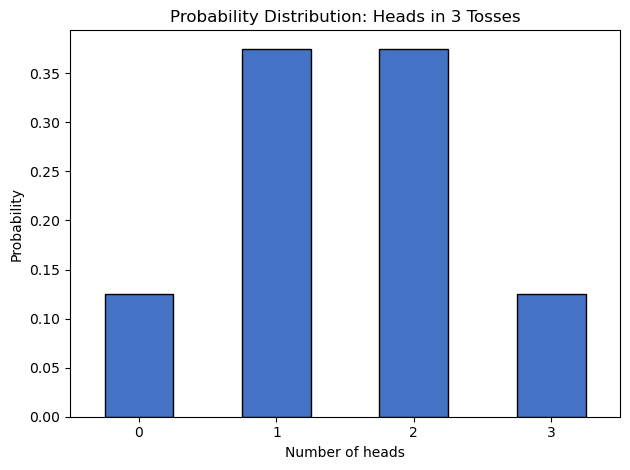

Probability sum: 1.0
Expected heads: 1.5


In [62]:
distribution.plot(kind="bar", color="#4472C4", edgecolor="black")
plt.title("Probability Distribution: Heads in 3 Tosses")
plt.xlabel("Number of heads")
plt.ylabel("Probability")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Probability sum:", distribution.sum())
print("Expected heads:", sum(x*p for x,p in distribution.items()))


## 8. Healthcare simulation mini-case (98–105 min)
A clinic schedules 10 appointments. For demonstration, assume each appointment independently has a 0.80 attendance probability.

Use simulation to estimate the distribution of daily attendance. This is a model, and its usefulness depends on whether the assumptions are reasonable.


### Theory: Binomial model
A binomial model is appropriate when:
1. There is a fixed number of trials, $n$.
2. Each trial has two outcomes, often labelled success and failure.
3. The probability $p$ is constant across trials.
4. Trials are independent.

For $X \sim \mathrm{Binomial}(n,p)$:

$$
P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}
$$

Real healthcare attendance may violate constant-probability or independence assumptions, so model limitations must be discussed.


In [129]:
appointments = 10
attendance_probability = 0.80
simulated_days = 100000000
attendance_counts = np.random.binomial(
    n=appointments,
    p=attendance_probability,
    size=simulated_days
)
print("Estimated average attendance:", round(attendance_counts.mean(), 3))
print("Estimated P(9 or more attend):", round(np.mean(attendance_counts >= 9), 3))
print("Estimated P(6 or fewer attend):", round(np.mean(attendance_counts <= 6), 3))


Estimated average attendance: 8.0
Estimated P(9 or more attend): 0.376
Estimated P(6 or fewer attend): 0.121


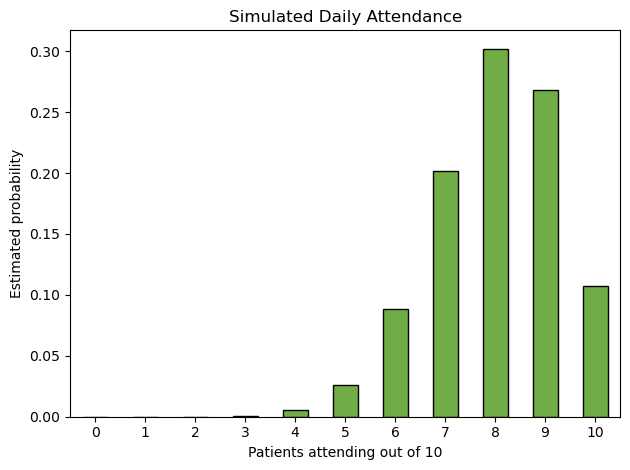

In [131]:
pd.Series(attendance_counts).value_counts(normalize=True).sort_index().plot(
    kind="bar", color="#70AD47", edgecolor="black"
)
plt.title("Simulated Daily Attendance")
plt.xlabel("Patients attending out of 10")
plt.ylabel("Estimated probability")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Decision Brief: maximum 50 words
Write three sentences:
1. One simulation result.
2. One operational use for staffing or scheduling.
3. One assumption or limitation that management must consider.

## Healthcare Probability Lab
A clinic schedules 20 patients per day. Historical analysis suggests different attendance probabilities:
- reminder received: 0.90
- no reminder: 0.65

Assume 12 scheduled patients receive reminders and 8 do not. For this classroom model, treat attendance outcomes as independent.

### Student Work
1. Calculate expected attendance in each group and overall.
2. Simulate 10,000 clinic days.
3. Estimate the probability that at least 17 patients attend.
4. Explain one operational finding and one limitation.


### Colab Exercise
Modify the reminder probability from `0.90` to `0.80`, rerun the simulation, and compare the estimated probability that at least 17 patients attend. Explain why the result changes.


<details><summary><strong>Click to show hint: Reminder-probability sensitivity</strong></summary>

Change only `reminder_p`, keep the remaining assumptions fixed, rerun the cells, and compare the two estimated probabilities.

</details>


<details><summary><strong>Click to show solution: Reminder-probability sensitivity</strong></summary>

A lower reminder-group attendance probability should generally lower total expected attendance and reduce the estimated chance that at least 17 patients attend. The exact simulation estimate may vary slightly unless the random seed is reset. This is a sensitivity comparison, not evidence that reminders cause attendance.

</details>


<details><summary><strong>Click to show explanation: Reminder-probability sensitivity</strong></summary>

Reducing the reminder-group probability from 0.90 to 0.80 lowers its expected attendance from 12×0.90=10.8 to 12×0.80=9.6. Total expected attendance falls from 16.0 to 14.8, so the probability of at least 17 attendees should also decrease. This sensitivity result is not causal evidence.

</details>


In [76]:
# STUDENT WORK
reminder_n, reminder_p = 12, 0.90
no_reminder_n, no_reminder_p = 8, 0.65

expected_reminder = reminder_n * reminder_p
expected_no_reminder = no_reminder_n * no_reminder_p
expected_total = expected_reminder + expected_no_reminder

sim_days = 10000
attendance_with_reminder = np.random.binomial(reminder_n, reminder_p, sim_days)
attendance_without_reminder = np.random.binomial(no_reminder_n, no_reminder_p, sim_days)
total_attendance = attendance_with_reminder + attendance_without_reminder

print("Expected with reminders:", expected_reminder)
print("Expected without reminders:", expected_no_reminder)
print("Expected total:", expected_total)
print("Estimated P(at least 17 attend):", round(np.mean(total_attendance >= 17), 3))


Expected with reminders: 10.8
Expected without reminders: 5.2
Expected total: 16.0
Estimated P(at least 17 attend): 0.399


<details><summary><strong>Click to show hint: Healthcare Probability Lab</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Healthcare Probability Lab</strong></summary>

Expected attendance is $12(0.90)=10.8$ for the reminder group and $8(0.65)=5.2$ for the no-reminder group, for an expected total of 16 patients.

The simulation estimates the probability of at least 17 attendees; the exact estimate can vary slightly by run. A decision-relevant pattern is that the group with reminders has the higher modeled attendance probability. However, the model does not prove reminders cause attendance, and independence plus fixed group probabilities may be unrealistic.

</details>


<details><summary><strong>Click to show explanation: Healthcare Probability Lab</strong></summary>

The expected total is 16, but 16 is a long-run average, not a guaranteed daily count. The simulation estimates uncertainty around that expectation under fixed-probability and independence assumptions.

</details>


## 9. Exit ticket (105–110 min)
1. What is the difference between an outcome and an event?
2. When can favourable outcomes be divided by total outcomes?
3. How do mutually exclusive and independent events differ?
4. What question helps distinguish a permutation from a combination?
5. Why is simulation useful, and why does it not remove uncertainty?


## Key takeaways
- Probability quantifies uncertainty under stated assumptions.
- Sample spaces and events organize possible outcomes.
- Experimental probability is an estimate based on repeated trials.
- Complements, unions, and intersections support combined-event reasoning.
- Counting rules simplify large sample spaces.
- Probability distributions connect uncertainty to predictive analytics decisions.


### Important language note
A large difference in modeled attendance probabilities can be important for planning, but this notebook does not establish a statistically significant causal effect of reminders. That would require an appropriate study design and inferential analysis.
